# CocoCare — Saved Model Evaluation & Architecture Comparison

**Purpose:** Independently evaluate the trained six-class coconut-health classifiers, compare architectures fairly, inspect errors, and generate evidence for a project presentation.

This notebook **does not train or modify models**. It loads saved `.keras` checkpoints and evaluates them on the existing fixed test split.

## Models expected
- MobileNetV3Small
- MobileNetV3Large
- EfficientNetB0 (only if its training completed successfully)
- ConvNeXtTiny

## Evaluation principles
1. Use the exact same `test.csv` and class order for every model.
2. Use the same image size and pixel range used during training: **224 × 224, float32, 0–255**.
3. Do not use the test set to tune hyperparameters or select thresholds.
4. Report macro-F1, balanced accuracy, per-class recall, confusion matrices and model efficiency—not accuracy alone.
5. Treat the test results as provisional if images from the same tree, farm, or capture session can occur in different splits.

> Important: the earlier training notebook selected checkpoints using validation loss. This notebook evaluates the saved `best_model.keras` files. It does not choose a new checkpoint based on test performance.

## 1. Configuration and paths

The default paths match the previous architecture-comparison notebook:

- `CocoCare/ml/data/processed/coconut_health_v2/splits/test.csv`
- `CocoCare/ml/models/architecture_comparison/<Architecture>/best_model.keras`

If automatic discovery fails, set `ML_ROOT` manually in the cell below.

In [19]:
from pathlib import Path
import os, json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42
np.random.seed(SEED)

# Option A: automatic discovery from the current directory or its parents.
cwd = Path.cwd().resolve()
ML_ROOT = None
for base in [cwd, *cwd.parents]:
    if base.name == "ml" and (base / "data").exists():
        ML_ROOT = base
        break
    if (base / "ml" / "data").exists():
        ML_ROOT = base / "ml"
        break

# Option B: uncomment and edit this if automatic discovery fails.
# ML_ROOT = Path("/absolute/path/to/CocoCare/ml")

if ML_ROOT is None:
    raise FileNotFoundError(
        f"Could not locate CocoCare/ml from {cwd}. "
        "Set ML_ROOT manually to the full path of the ml folder."
    )

DATA_ROOT = ML_ROOT / "data" / "processed" / "coconut_health_v2"
SPLIT_ROOT = DATA_ROOT / "splits"
MODEL_ROOT = ML_ROOT / "models" / "architecture_comparison"
RESULT_ROOT = ML_ROOT / "results" / "model_evaluation"
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

TEST_CSV = SPLIT_ROOT / "test.csv"

print("Python:", platform.python_version())
print("Working directory:", cwd)
print("ML_ROOT:", ML_ROOT)
print("Test CSV:", TEST_CSV, "| exists:", TEST_CSV.exists())
print("Model directory:", MODEL_ROOT, "| exists:", MODEL_ROOT.exists())
print("Results will be saved to:", RESULT_ROOT)

if not TEST_CSV.exists():
    raise FileNotFoundError(f"Missing test split: {TEST_CSV}")
if not MODEL_ROOT.exists():
    raise FileNotFoundError(f"Missing model directory: {MODEL_ROOT}")

Python: 3.12.14
Working directory: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/notebooks
ML_ROOT: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml
Test CSV: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/processed/coconut_health_v2/splits/test.csv | exists: True
Model directory: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/models/architecture_comparison | exists: True
Results will be saved to: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/results/model_evaluation


## 2. Load libraries, check hardware and define the class order

The class order must match the original training notebook exactly. A different class order can produce incorrect labels even when the model weights are correct.

In [20]:
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    matthews_corrcoef, cohen_kappa_score, top_k_accuracy_score
)

CLASS_NAMES = [
    "healthy",
    "bud_root_dropping",
    "bud_rot",
    "gray_leaf_spot",
    "leaf_rot",
    "stem_bleeding",
]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}
INDEX_TO_CLASS = {i: name for name, i in CLASS_TO_INDEX.items()}

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Class order:", CLASS_NAMES)

TensorFlow: 2.21.0
Available GPUs: []
Class order: ['healthy', 'bud_root_dropping', 'bud_rot', 'gray_leaf_spot', 'leaf_rot', 'stem_bleeding']


## 3. Load and validate the fixed test split

This cell checks:
- required CSV columns;
- valid class names;
- image paths exist;
- all six classes are represented;
- duplicate file hashes within the test set.

It also prints the test support per class. Support matters: a metric calculated from very few healthy images has substantial uncertainty.

In [21]:
test_df = pd.read_csv(TEST_CSV).copy()
required_columns = {"path", "class_name"}
missing_columns = required_columns - set(test_df.columns)
if missing_columns:
    raise ValueError(f"test.csv is missing columns: {missing_columns}")

test_df["path"] = test_df["path"].astype(str)
unknown_classes = sorted(set(test_df["class_name"]) - set(CLASS_NAMES))
if unknown_classes:
    raise ValueError(f"Unexpected class names in test.csv: {unknown_classes}")

missing_paths = [p for p in test_df["path"] if not Path(p).is_file()]
if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} test image paths do not exist. Example: {missing_paths[0]}"
    )

test_df["label"] = test_df["class_name"].map(CLASS_TO_INDEX).astype(int)
support = (
    test_df["class_name"].value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
    .rename("test_images")
    .to_frame()
)
display(support)
print("Total test images:", len(test_df))

if (support["test_images"] == 0).any():
    raise ValueError("At least one class is absent from the test split.")

,test_images
class_name,
healthy,18
bud_root_dropping,77
bud_rot,71
gray_leaf_spot,316
leaf_rot,251
stem_bleeding,151


Total test images: 884


In [22]:
import hashlib

def sha256_file(file_path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

test_hashes = test_df["path"].map(sha256_file)
duplicate_count = int(test_hashes.duplicated().sum())
print("Exact duplicate files within test split:", duplicate_count)
if duplicate_count:
    print("WARNING: duplicated test images can inflate reported performance.")
print(
    "Reminder: this does not detect resized/cropped near-duplicates, "
    "same-tree images, or source/farm leakage across train/validation/test."
)

Exact duplicate files within test split: 0
Reminder: this does not detect resized/cropped near-duplicates, same-tree images, or source/farm leakage across train/validation/test.


## 4. Build the test input pipeline

The previous training notebook used images resized to 224 × 224 and passed as float32 values in the **0–255 range**. The Keras Application backbones contain their own preprocessing layers in that experiment.

Do not divide by 255 again here. Double normalization would change the input distribution and invalidate the comparison.

In [23]:
def decode_resize(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Preserve 0..255 range.
    return image, label

test_ds = (
    tf.data.Dataset.from_tensor_slices((
        test_df["path"].values,
        test_df["label"].values.astype("int32")
    ))
    .map(decode_resize, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# One batch sanity check
sample_images, sample_labels = next(iter(test_ds))
print("Batch image shape:", sample_images.shape)
print("Pixel range:", float(tf.reduce_min(sample_images)), "to", float(tf.reduce_max(sample_images)))
print("Label batch shape:", sample_labels.shape)

Batch image shape: (16, 224, 224, 3)
Pixel range: 0.0 to 255.00003051757812
Label batch shape: (16,)


## 5. Discover available trained models

A model is included only if its saved `best_model.keras` checkpoint exists. EfficientNetB0 will be skipped automatically if its earlier training failed and no checkpoint was saved.

In [24]:
ARCHITECTURES = [
    "MobileNetV3Small",
    "MobileNetV3Large",
    "EfficientNetB0",
    "ConvNeXtTiny",
]

MODEL_PATHS = {
    name: MODEL_ROOT / name / "best_model.keras"
    for name in ARCHITECTURES
}

available_models = {
    name: path for name, path in MODEL_PATHS.items() if path.is_file()
}
missing_models = [name for name, path in MODEL_PATHS.items() if not path.is_file()]

print("Available checkpoints:")
for name, path in available_models.items():
    print(" ✓", name, "->", path)

print("\nNot available:")
for name in missing_models:
    print(" -", name, "(checkpoint not found; skipped)")

if not available_models:
    raise FileNotFoundError(
        "No best_model.keras files found. Check MODEL_ROOT and the training outputs."
    )

Available checkpoints:
 ✓ MobileNetV3Small -> /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/models/architecture_comparison/MobileNetV3Small/best_model.keras
 ✓ MobileNetV3Large -> /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/models/architecture_comparison/MobileNetV3Large/best_model.keras
 ✓ ConvNeXtTiny -> /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/models/architecture_comparison/ConvNeXtTiny/best_model.keras

Not available:
 - EfficientNetB0 (checkpoint not found; skipped)


## 6. Evaluation functions and metric definitions

We report the following:

| Metric | What it tells us | Why it matters |
|---|---|---|
| Accuracy | Fraction of all images classified correctly | Easy overall summary, but can hide class imbalance |
| Macro precision | Average precision across classes, giving each class equal weight | Penalizes unreliable class predictions |
| Macro recall / balanced accuracy | Average recall across classes | Shows whether minority classes are being missed |
| Macro F1 | Harmonic mean of precision and recall, averaged equally across classes | Main balanced classification comparison |
| Weighted F1 | F1 weighted by class support | Reflects the test-set class distribution |
| Per-class recall | Fraction of each actual class correctly identified | Especially important for disease misses |
| MCC | Overall correlation between true and predicted labels | Useful single-number multiclass summary |
| Top-2 accuracy | Correct class is among the two highest scores | Secondary diagnostic, not a replacement for top-1 accuracy |

Specificity is also calculated one-vs-rest for each class. Confidence is the maximum softmax output; it is **not automatically a calibrated probability**.

In [25]:
def expected_calibration_error(y_true, probs, n_bins=10):
    confidence = probs.max(axis=1)
    predicted = probs.argmax(axis=1)
    correct = (predicted == y_true).astype(float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        # Include confidence=1.0 in the last bin.
        mask = (confidence >= lo) & (
            (confidence < hi) if hi < 1.0 else (confidence <= hi)
        )
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(ece)

def calculate_metrics(y_true, probs):
    y_pred = probs.argmax(axis=1)
    labels = np.arange(len(CLASS_NAMES))
    p, r, f1, support_values = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    per_class_specificity = []
    for i in labels:
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp
        per_class_specificity.append(tn / (tn + fp) if (tn + fp) else np.nan)

    summary = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_precision": float(np.mean(p)),
        "macro_recall": float(np.mean(r)),
        "macro_f1": float(np.mean(f1)),
        "weighted_f1": float(precision_recall_fscore_support(
            y_true, y_pred, average="weighted", zero_division=0
        )[2]),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "cohen_kappa": float(cohen_kappa_score(y_true, y_pred)),
        "top2_accuracy": float(top_k_accuracy_score(
            y_true, probs, k=2, labels=labels
        )),
        "ece_10_bins": expected_calibration_error(y_true, probs),
    }

    per_class = pd.DataFrame({
        "class": CLASS_NAMES,
        "precision": p,
        "recall": r,
        "f1": f1,
        "specificity_ovr": per_class_specificity,
        "support": support_values,
    })
    return summary, per_class, cm, y_pred

## 7. Benchmark inference time

Inference time is measured for a single image after warm-up. It includes model-call overhead and is intended as a relative comparison on this machine—not a universal hardware benchmark.

All models are benchmarked in the same Python/TensorFlow process and on the same available device. For a publication-quality latency claim, repeat on the target deployment device and report its CPU/GPU, software versions, thread settings, and number of repetitions.

In [26]:
def benchmark_single_image(model, image_tensor, warmup=10, repeats=100):
    x = tf.expand_dims(image_tensor, axis=0)

    # Warm-up: initialize kernels and avoid first-call compilation cost.
    for _ in range(warmup):
        _ = model(x, training=False).numpy()

    timings_ms = []
    for _ in range(repeats):
        start = time.perf_counter()
        _ = model(x, training=False).numpy()  # .numpy() synchronizes execution
        timings_ms.append((time.perf_counter() - start) * 1000)

    return {
        "latency_mean_ms": float(np.mean(timings_ms)),
        "latency_median_ms": float(np.median(timings_ms)),
        "latency_p95_ms": float(np.percentile(timings_ms, 95)),
    }

## 8. Evaluate every available architecture

For each saved checkpoint, this cell:
- loads the model without requiring its original optimizer state;
- predicts the exact same test images;
- calculates the same metrics;
- saves per-image predictions and per-class metrics;
- saves the confusion matrix;
- records parameter count, `.keras` file size and inference latency.

If a model fails to load or predict, the error is recorded and the other models continue.

In [27]:
all_summaries = []
all_per_class = {}
all_confusion = {}
all_predictions = {}
all_probabilities = {}
evaluation_errors = []

for architecture, model_path in available_models.items():
    print("\n" + "=" * 72)
    print("Evaluating:", architecture)
    print("=" * 72)
    try:
        model = tf.keras.models.load_model(model_path, compile=False)

        # Confirm the model output matches the six expected classes.
        output_shape = model.output_shape
        if isinstance(output_shape, list) or output_shape[-1] != len(CLASS_NAMES):
            raise ValueError(
                f"Expected {len(CLASS_NAMES)} output classes, got {output_shape}"
            )

        probs = model.predict(test_ds, verbose=1)
        if probs.shape != (len(test_df), len(CLASS_NAMES)):
            raise ValueError(f"Unexpected prediction shape: {probs.shape}")
        if not np.isfinite(probs).all():
            raise ValueError("Predictions contain NaN or infinite values.")

        # Softmax sanity check. The training notebook uses a six-class softmax head.
        row_sums = probs.sum(axis=1)
        if not np.allclose(row_sums, 1.0, atol=1e-3):
            warnings.warn(
                f"{architecture}: output rows do not sum closely to 1. "
                "Check the saved model output activation."
            )

        y_true = test_df["label"].to_numpy()
        summary, per_class, cm, y_pred = calculate_metrics(y_true, probs)

        keras_size_mb = model_path.stat().st_size / (1024 ** 2)
        params = int(model.count_params())
        latency = benchmark_single_image(
            model, sample_images[0], warmup=10, repeats=100
        )

        summary.update({
            "architecture": architecture,
            "parameters": params,
            "keras_size_mb": keras_size_mb,
            **latency,
            "test_images": len(test_df),
            "model_path": str(model_path),
        })

        arch_result_dir = RESULT_ROOT / architecture
        arch_result_dir.mkdir(parents=True, exist_ok=True)

        per_class.to_csv(arch_result_dir / "per_class_metrics.csv", index=False)
        pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            arch_result_dir / "confusion_matrix.csv"
        )

        prediction_df = test_df[["path", "class_name"]].copy()
        prediction_df["true_label"] = [INDEX_TO_CLASS[i] for i in y_true]
        prediction_df["predicted_label"] = [INDEX_TO_CLASS[i] for i in y_pred]
        prediction_df["confidence"] = probs.max(axis=1)
        prediction_df["correct"] = y_true == y_pred
        prediction_df["top2_margin"] = (
            np.sort(probs, axis=1)[:, -1] - np.sort(probs, axis=1)[:, -2]
        )
        prediction_df.to_csv(arch_result_dir / "predictions.csv", index=False)

        with open(arch_result_dir / "summary.json", "w") as f:
            json.dump(summary, f, indent=2)

        all_summaries.append(summary)
        all_per_class[architecture] = per_class
        all_confusion[architecture] = cm
        all_predictions[architecture] = prediction_df
        all_probabilities[architecture] = probs

        print("Accuracy:", round(summary["accuracy"], 4))
        print("Macro F1:", round(summary["macro_f1"], 4))
        print("Balanced accuracy:", round(summary["balanced_accuracy"], 4))
        print("Healthy recall:", round(
            float(per_class.loc[per_class["class"] == "healthy", "recall"].iloc[0]), 4
        ))
        print("Parameters:", f"{params:,}")
        print("Mean single-image latency (ms):", round(latency["latency_mean_ms"], 2))

        del model
        tf.keras.backend.clear_session()

    except Exception as exc:
        evaluation_errors.append({
            "architecture": architecture,
            "error": repr(exc),
        })
        print("EVALUATION FAILED:", repr(exc))
        tf.keras.backend.clear_session()

if not all_summaries:
    raise RuntimeError("No models completed evaluation. See the errors above.")

summary_df = pd.DataFrame(all_summaries)
summary_df.to_csv(RESULT_ROOT / "model_comparison_summary.csv", index=False)
if evaluation_errors:
    pd.DataFrame(evaluation_errors).to_csv(
        RESULT_ROOT / "evaluation_errors.csv", index=False
    )

display(summary_df.sort_values("macro_f1", ascending=False))
print("Results saved to:", RESULT_ROOT)


Evaluating: MobileNetV3Small
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 129ms/step
Accuracy: 0.9966
Macro F1: 0.9973
Balanced accuracy: 0.9981
Healthy recall: 1.0
Parameters: 942,582
Mean single-image latency (ms): 127.78

Evaluating: MobileNetV3Large
56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 361ms/step
Accuracy: 0.9989
Macro F1: 0.9985
Balanced accuracy: 0.9993
Healthy recall: 1.0
Parameters: 3,002,118
Mean single-image latency (ms): 198.55

Evaluating: ConvNeXtTiny
56/56 ━━━━━━━━━━━━━━━━━━━━ 316s 6s/step
Accuracy: 0.9977
Macro F1: 0.9979
Balanced accuracy: 0.9987
Healthy recall: 1.0
Parameters: 27,824,742
Mean single-image latency (ms): 728.84


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,cohen_kappa,top2_accuracy,ece_10_bins,architecture,parameters,keras_size_mb,latency_mean_ms,latency_median_ms,latency_p95_ms,test_images,model_path
1,0.998869,0.999336,0.997685,0.999336,0.998502,0.998872,0.998490,0.998488,0.998869,0.001216,MobileNetV3Large,3002118,27.138518,198.552541,177.872964,282.511713,884,/run/media/sivabharathi/ssd/storage/finalYear/...
2,0.997738,0.998672,0.997159,0.998672,0.997905,0.997738,0.996981,0.996976,0.998869,0.001273,ConvNeXtTiny,27824742,229.261183,728.839187,726.229257,751.746119,884,/run/media/sivabharathi/ssd/storage/finalYear/...
0,0.996606,0.998145,0.996491,0.998145,0.997309,0.996607,0.995466,0.995464,0.998869,0.001436,MobileNetV3Small,942582,8.636438,127.776074,126.856939,129.839357,884,/run/media/sivabharathi/ssd/storage/finalYear/...


Results saved to: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/results/model_evaluation


## 9. Compare confusion matrices

Rows are actual classes; columns are predicted classes. Diagonal values are correct predictions. Off-diagonal values show which classes are confused.

For disease screening, pay particular attention to:
- actual diseased images predicted as healthy (missed disease);
- actual healthy images predicted as diseased (false alarms);
- repeated confusion between visually similar disease classes.

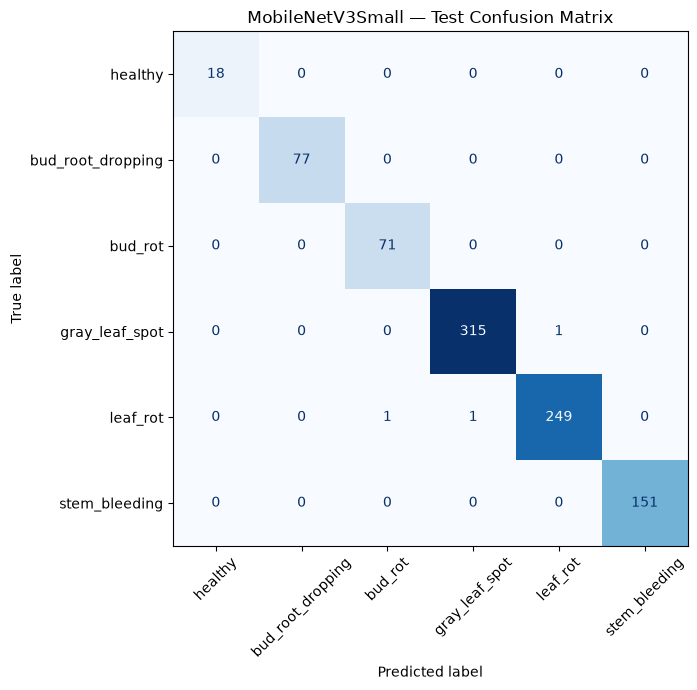

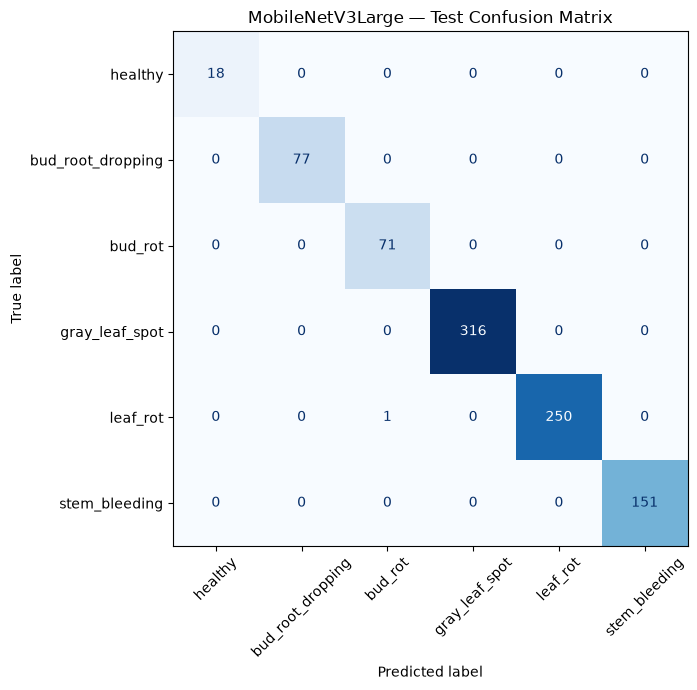

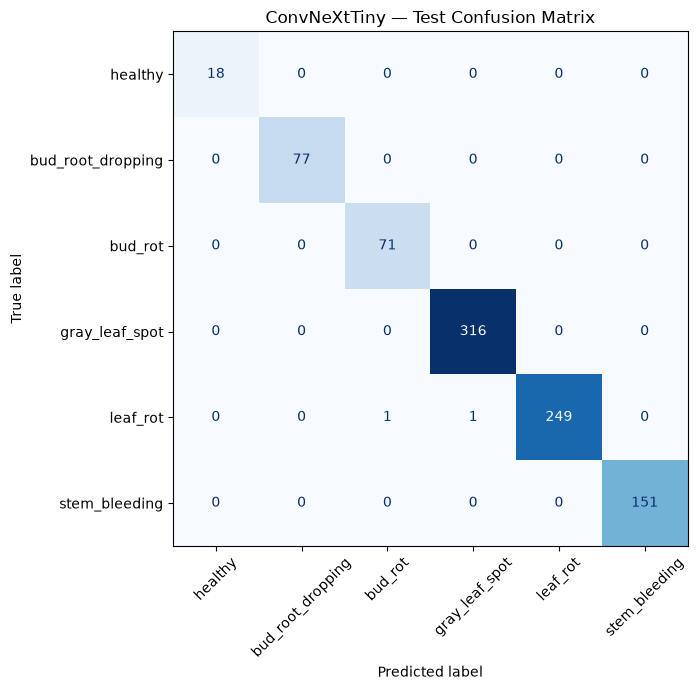

In [28]:
for architecture, cm in all_confusion.items():
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    ).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{architecture} — Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(RESULT_ROOT / f"{architecture}_confusion_matrix.png", dpi=180)
    plt.show()

## 10. Compare per-class precision, recall and F1

A strong overall score can hide a weak class. The table below puts each model's class-wise recall side by side.

For CocoCare, **healthy recall alone is not enough**: also inspect disease recall. A diseased tree predicted as healthy is a potentially important false negative.

In [29]:
for metric in ["precision", "recall", "f1", "specificity_ovr"]:
    wide = pd.DataFrame({
        architecture: df.set_index("class")[metric]
        for architecture, df in all_per_class.items()
    }).reindex(CLASS_NAMES)
    print("\n", metric.upper())
    display(wide.round(4))
    wide.to_csv(RESULT_ROOT / f"per_class_{metric}_comparison.csv")


 PRECISION


,MobileNetV3Small,MobileNetV3Large,ConvNeXtTiny
class,,,
healthy,1.0000,1.0000,1.0000
bud_root_dropping,1.0000,1.0000,1.0000
bud_rot,0.9861,0.9861,0.9861
gray_leaf_spot,0.9968,1.0000,0.9968
leaf_rot,0.9960,1.0000,1.0000
stem_bleeding,1.0000,1.0000,1.0000



 RECALL


,MobileNetV3Small,MobileNetV3Large,ConvNeXtTiny
class,,,
healthy,1.0000,1.000,1.000
bud_root_dropping,1.0000,1.000,1.000
bud_rot,1.0000,1.000,1.000
gray_leaf_spot,0.9968,1.000,1.000
leaf_rot,0.9920,0.996,0.992
stem_bleeding,1.0000,1.000,1.000



 F1


,MobileNetV3Small,MobileNetV3Large,ConvNeXtTiny
class,,,
healthy,1.0000,1.000,1.0000
bud_root_dropping,1.0000,1.000,1.0000
bud_rot,0.9930,0.993,0.9930
gray_leaf_spot,0.9968,1.000,0.9984
leaf_rot,0.9940,0.998,0.9960
stem_bleeding,1.0000,1.000,1.0000



 SPECIFICITY_OVR


,MobileNetV3Small,MobileNetV3Large,ConvNeXtTiny
class,,,
healthy,1.0000,1.0000,1.0000
bud_root_dropping,1.0000,1.0000,1.0000
bud_rot,0.9988,0.9988,0.9988
gray_leaf_spot,0.9982,1.0000,0.9982
leaf_rot,0.9984,1.0000,1.0000
stem_bleeding,1.0000,1.0000,1.0000


## 11. Visual comparison of key metrics

Macro-F1 and balanced accuracy are useful primary comparison metrics when classes are imbalanced. Accuracy is shown for context, not as the only selection criterion.

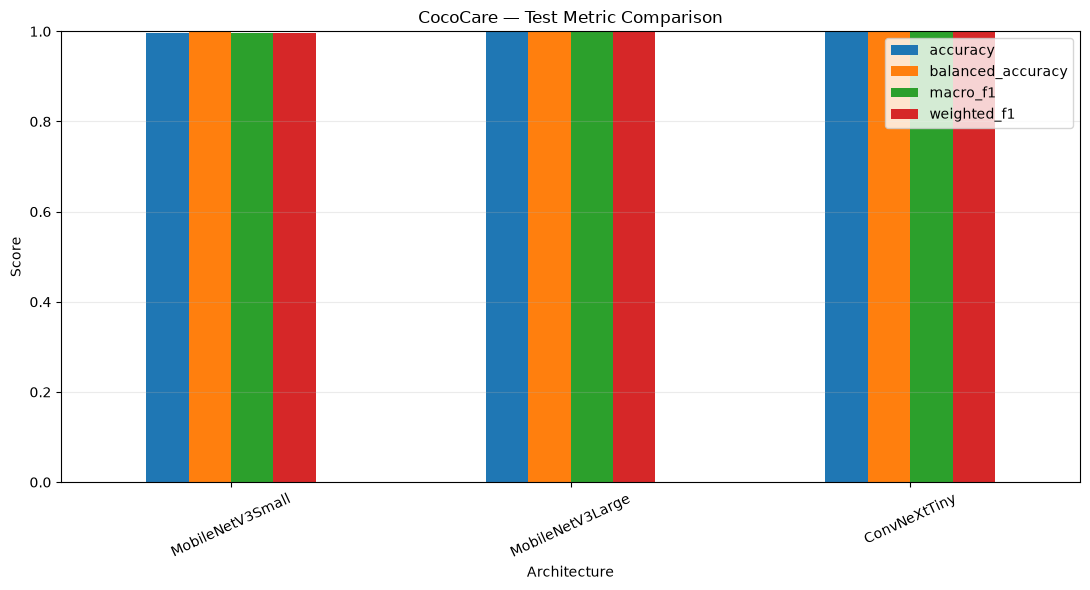

,accuracy,balanced_accuracy,macro_f1,weighted_f1
architecture,,,,
MobileNetV3Small,0.9966,0.9981,0.9973,0.9966
MobileNetV3Large,0.9989,0.9993,0.9985,0.9989
ConvNeXtTiny,0.9977,0.9987,0.9979,0.9977


In [30]:
plot_metrics = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]
plot_df = summary_df.set_index("architecture")[plot_metrics]

ax = plot_df.plot(kind="bar", figsize=(11, 6), ylim=(0, 1))
ax.set_title("CocoCare — Test Metric Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Architecture")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULT_ROOT / "architecture_metric_comparison.png", dpi=180)
plt.show()

display(plot_df.round(4))

## 12. Model efficiency comparison

This table compares parameter count, saved Keras checkpoint size and single-image latency measured on the current machine.

- **Parameters** describe model capacity, not the exact memory required at runtime.
- **Checkpoint size** is not the same as RAM usage or final TFLite size.
- **Latency** depends on hardware, TensorFlow build, threading, and warm-up.
- A smaller model can be preferable for mobile deployment if its disease-class performance is sufficiently strong.

In [31]:
efficiency_cols = [
    "architecture", "parameters", "keras_size_mb",
    "latency_mean_ms", "latency_median_ms", "latency_p95_ms"
]
efficiency_df = summary_df[efficiency_cols].copy()
efficiency_df["parameters_millions"] = efficiency_df["parameters"] / 1e6
display(efficiency_df.round(3))
efficiency_df.to_csv(RESULT_ROOT / "model_efficiency_comparison.csv", index=False)

,architecture,parameters,keras_size_mb,latency_mean_ms,latency_median_ms,latency_p95_ms,parameters_millions
0,MobileNetV3Small,942582,8.636,127.776,126.857,129.839,0.943
1,MobileNetV3Large,3002118,27.139,198.553,177.873,282.512,3.002
2,ConvNeXtTiny,27824742,229.261,728.839,726.229,751.746,27.825


## 13. Inspect the most important errors

This cell lists incorrect predictions and low-confidence predictions for each model. Open the images and inspect whether the model is focusing on disease symptoms, growth stage, background, lighting, or image quality.

Softmax confidence is not a guarantee of correctness. A confidently wrong prediction is especially important to investigate.

In [32]:
for architecture, pred_df in all_predictions.items():
    errors = pred_df.loc[~pred_df["correct"]].sort_values("confidence", ascending=False)
    uncertain = pred_df.loc[pred_df["confidence"] < 0.80].sort_values("confidence")

    print("\n" + architecture)
    print("Incorrect predictions:", len(errors), "/", len(pred_df))
    print("Predictions with confidence < 0.80:", len(uncertain))

    if len(errors):
        display(errors[[
            "path", "true_label", "predicted_label", "confidence"
        ]].head(20))


MobileNetV3Small
Incorrect predictions: 3 / 884
Predictions with confidence < 0.80: 2


,path,true_label,predicted_label,confidence
244,/run/media/sivabharathi/ssd/storage/finalYear/...,leaf_rot,bud_rot,0.999998
249,/run/media/sivabharathi/ssd/storage/finalYear/...,leaf_rot,gray_leaf_spot,0.977635
660,/run/media/sivabharathi/ssd/storage/finalYear/...,gray_leaf_spot,leaf_rot,0.608488



MobileNetV3Large
Incorrect predictions: 1 / 884
Predictions with confidence < 0.80: 0


,path,true_label,predicted_label,confidence
244,/run/media/sivabharathi/ssd/storage/finalYear/...,leaf_rot,bud_rot,1.0



ConvNeXtTiny
Incorrect predictions: 2 / 884
Predictions with confidence < 0.80: 1


,path,true_label,predicted_label,confidence
244,/run/media/sivabharathi/ssd/storage/finalYear/...,leaf_rot,bud_rot,0.999993
249,/run/media/sivabharathi/ssd/storage/finalYear/...,leaf_rot,gray_leaf_spot,0.545217


## 14. Visual audit of misclassified images

Use this to examine a small sample of errors from the selected architecture. Change `INSPECT_MODEL` if needed. This is a human review step: record whether the label is correct, whether the image is ambiguous, and whether the disease symptom is visible.

Inspecting errors from: MobileNetV3Large


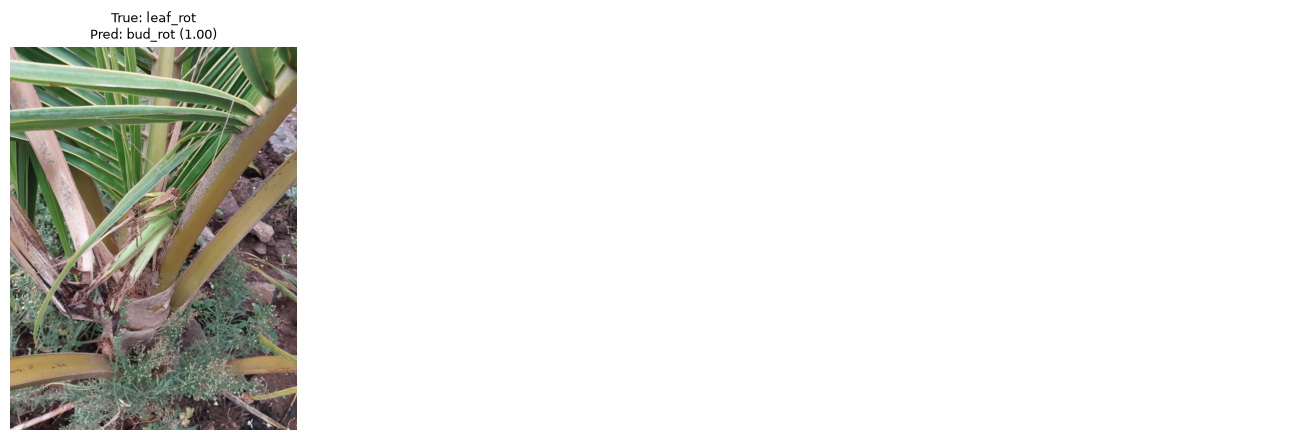

In [33]:
INSPECT_MODEL = max(all_summaries, key=lambda row: row["macro_f1"])["architecture"]
MAX_IMAGES_TO_SHOW = 12

error_rows = all_predictions[INSPECT_MODEL]
error_rows = error_rows.loc[~error_rows["correct"]].head(MAX_IMAGES_TO_SHOW)

print("Inspecting errors from:", INSPECT_MODEL)
if error_rows.empty:
    print("No misclassified images in this test set.")
else:
    ncols = 3
    nrows = int(np.ceil(len(error_rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, error_rows.iterrows()):
        img = Image.open(row["path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"True: {row['true_label']}\n"
            f"Pred: {row['predicted_label']} ({row['confidence']:.2f})",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[len(error_rows):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## 15. Healthy-versus-diseased screening analysis

For this analysis, the five disease classes are grouped as **diseased** and compared against **healthy**. This is a derived binary view of the six-class model, not a separately trained binary classifier.

We report:
- healthy recall: how often healthy images are recognized as healthy;
- diseased recall: how often diseased images are recognized as some disease;
- healthy precision: how reliable the model's healthy predictions are;
- disease-to-healthy false negatives: diseased images predicted as healthy.

In [34]:
binary_rows = []
for architecture, pred_df in all_predictions.items():
    actual_healthy = pred_df["true_label"].eq("healthy").to_numpy()
    predicted_healthy = pred_df["predicted_label"].eq("healthy").to_numpy()

    healthy_tp = int(np.sum(actual_healthy & predicted_healthy))
    healthy_fn = int(np.sum(actual_healthy & ~predicted_healthy))
    healthy_fp = int(np.sum(~actual_healthy & predicted_healthy))
    diseased_total = int((~actual_healthy).sum())
    healthy_total = int(actual_healthy.sum())

    healthy_recall = healthy_tp / healthy_total if healthy_total else np.nan
    healthy_precision = healthy_tp / (healthy_tp + healthy_fp) if (healthy_tp + healthy_fp) else np.nan
    diseased_recall = (diseased_total - healthy_fp) / diseased_total if diseased_total else np.nan

    binary_rows.append({
        "architecture": architecture,
        "healthy_recall": healthy_recall,
        "healthy_precision": healthy_precision,
        "diseased_recall": diseased_recall,
        "healthy_images_misclassified": healthy_fn,
        "diseased_images_predicted_healthy": healthy_fp,
        "healthy_test_support": healthy_total,
        "diseased_test_support": diseased_total,
    })

binary_df = pd.DataFrame(binary_rows)
display(binary_df.round(4))
binary_df.to_csv(RESULT_ROOT / "healthy_vs_diseased_summary.csv", index=False)

,architecture,healthy_recall,healthy_precision,diseased_recall,healthy_images_misclassified,diseased_images_predicted_healthy,healthy_test_support,diseased_test_support
0,MobileNetV3Small,1.0,1.0,1.0,0,0,18,866
1,MobileNetV3Large,1.0,1.0,1.0,0,0,18,866
2,ConvNeXtTiny,1.0,1.0,1.0,0,0,18,866


## 16. Make a transparent provisional recommendation

This cell ranks models by macro-F1, but does **not** automatically declare a clinically or agronomically reliable model. A final choice must also consider:
- no unacceptable disease class recall;
- healthy/diseased errors;
- test-set support and confidence intervals;
- external testing on images from new trees/farms;
- deployment constraints (size and latency).

Use the recommendation as an experiment summary, not as proof of real-world readiness.

In [35]:
ranked = summary_df.sort_values(
    ["macro_f1", "balanced_accuracy", "latency_mean_ms"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(ranked[[
    "architecture", "accuracy", "balanced_accuracy",
    "macro_f1", "weighted_f1", "mcc",
    "parameters", "keras_size_mb", "latency_mean_ms"
]].round(4))

provisional_best = ranked.iloc[0]
print("\nProvisional highest macro-F1 model:", provisional_best["architecture"])
print("Macro-F1:", round(float(provisional_best["macro_f1"]), 4))
print("Balanced accuracy:", round(float(provisional_best["balanced_accuracy"]), 4))
print(
    "This is a provisional ranking on the current test split. "
    "Do not claim real-world readiness without independent external validation."
)

,architecture,accuracy,balanced_accuracy,macro_f1,weighted_f1,mcc,parameters,keras_size_mb,latency_mean_ms
0,MobileNetV3Large,0.9989,0.9993,0.9985,0.9989,0.9985,3002118,27.1385,198.5525
1,ConvNeXtTiny,0.9977,0.9987,0.9979,0.9977,0.9970,27824742,229.2612,728.8392
2,MobileNetV3Small,0.9966,0.9981,0.9973,0.9966,0.9955,942582,8.6364,127.7761



Provisional highest macro-F1 model: MobileNetV3Large
Macro-F1: 0.9985
Balanced accuracy: 0.9993
This is a provisional ranking on the current test split. Do not claim real-world readiness without independent external validation.


## 17. Presentation-ready explanation: how the model works

Use the following explanation when presenting the experiment.

### A. Transfer learning
We use convolutional neural networks (CNNs) initialized with ImageNet pretrained weights. These networks already contain filters that respond to visual patterns such as edges, textures, shapes and color transitions. We adapt those learned representations to the six coconut-health classes.

### B. Two training phases
1. **Feature extraction:** freeze the pretrained backbone and train the new classification head. This adapts the final classifier to our coconut dataset while preserving the general pretrained features.
2. **Fine-tuning:** unfreeze approximately the last 20% of the backbone layers and train with a smaller learning rate. This allows higher-level visual features to adapt to coconut disease patterns. Batch-normalization layers remain frozen in the previous experiment.

### C. Classification head
The model's feature maps are passed through global average pooling, dropout, and a dense layer with six softmax outputs. The softmax scores sum to approximately 1 and represent the model's relative class scores.

### D. Training controls
- Input resolution: 224 × 224
- Batch size: 8 in the original training notebook
- Optimizer: Adam
- Initial head learning rate: 1e-3
- Fine-tuning learning rate: 1e-5
- Loss: sparse categorical cross-entropy
- Class weights: balanced weights calculated from training labels
- Augmentation: random horizontal flip, rotation, zoom and contrast
- Checkpoint selection: lowest validation loss, not test accuracy

### E. What each architecture contributes
- **MobileNetV3Small:** compact architecture designed for efficiency; useful when mobile speed and size matter.
- **MobileNetV3Large:** larger MobileNet variant; may offer a stronger accuracy/efficiency trade-off at a higher computational cost.
- **EfficientNetB0:** balances network depth, width and input resolution using compound scaling.
- **ConvNeXtTiny:** modernized convolutional architecture with a larger parameter count; can be computationally heavier.

### F. How prediction happens
1. Load a coconut image.
2. Resize it to 224 × 224.
3. Convert pixels to float32 in the 0–255 range.
4. Pass the image through the trained CNN.
5. Obtain six softmax scores.
6. Select the class with the highest score as the predicted class.
7. Review confidence and uncertainty; do not treat the largest softmax score as guaranteed certainty.

### G. Why macro-F1 is important
If one class has many more images than another, accuracy and weighted F1 can be dominated by the larger classes. Macro-F1 calculates F1 separately for every class and averages them equally. This makes it useful for comparing performance across imbalanced classes.

## 18. Presentation-ready result table

Run this after evaluation. It creates a compact table suitable for a report or slide. Replace the values only with results generated by this notebook.

In [36]:
presentation_columns = [
    "architecture", "accuracy", "macro_precision", "macro_recall",
    "macro_f1", "weighted_f1", "mcc", "parameters",
    "keras_size_mb", "latency_mean_ms"
]
presentation_table = ranked[presentation_columns].copy()
presentation_table = presentation_table.rename(columns={
    "architecture": "Model",
    "accuracy": "Accuracy",
    "macro_precision": "Macro Precision",
    "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
    "mcc": "MCC",
    "parameters": "Parameters",
    "keras_size_mb": "Checkpoint size (MB)",
    "latency_mean_ms": "Mean latency (ms/image)",
})
display(presentation_table.round(4))
presentation_table.to_csv(
    RESULT_ROOT / "presentation_comparison_table.csv", index=False
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,MCC,Parameters,Checkpoint size (MB),Mean latency (ms/image)
0,MobileNetV3Large,0.9989,0.9977,0.9993,0.9985,0.9989,0.9985,3002118,27.1385,198.5525
1,ConvNeXtTiny,0.9977,0.9972,0.9987,0.9979,0.9977,0.9970,27824742,229.2612,728.8392
2,MobileNetV3Small,0.9966,0.9965,0.9981,0.9973,0.9966,0.9955,942582,8.6364,127.7761


## 19. Limitations and next experiments

The results from this notebook are only as reliable as the dataset split and labels.

1. **Small healthy class:** the earlier experiment had only 18 healthy test images. A 100% score on 18 examples is encouraging but not enough to claim reliable healthy-tree recognition.
2. **Class weighting:** class weights compensate for different class counts during training; they do not create new examples or fix stage/source imbalance.
3. **Growth-stage confounding:** if particular disease labels occur mostly in one tree age or growth stage, a model may learn stage-related appearance rather than disease symptoms. Add verified growth-stage metadata and inspect the class-by-stage distribution.
4. **Source/background confounding:** dataset-specific backgrounds, cameras, watermarks, and lighting can become shortcuts.
5. **Leakage:** exact hashes do not detect near-duplicates or images from the same tree. Prefer grouping by tree, farm, or capture session when splitting.
6. **External validation:** evaluate on newly collected, independently labelled images from unseen trees and locations.
7. **Confidence calibration:** softmax scores should be calibrated and thresholds selected using validation data—not the final test set.
8. **Disease severity:** a six-class disease classifier does not automatically estimate early/moderate/severe disease stage.
9. **Not object detection:** this model classifies the whole image; it does not localize diseased regions with bounding boxes.

### Recommended next study
Create an external test set with balanced, expert-verified healthy and diseased images across relevant coconut growth stages, farms, lighting conditions and camera devices. Keep it untouched until the final evaluation.

## 20. Final checklist before presenting

- [ ] All models were evaluated on the exact same test CSV.
- [ ] Input preprocessing matches the original training notebook.
- [ ] Class order was verified.
- [ ] Per-class precision, recall and F1 were reviewed.
- [ ] Confusion matrices were inspected.
- [ ] Healthy-to-disease and disease-to-healthy errors were counted.
- [ ] Model size and latency were measured on the stated hardware.
- [ ] Test support—especially healthy support—was disclosed.
- [ ] Limitations around data leakage, growth stages and external validation were stated.
- [ ] The best model was selected using a balanced performance/deployment argument, not accuracy alone.

**Final reporting language:** “On the fixed held-out test split, [model] achieved [macro-F1] macro-F1 and [balanced accuracy] balanced accuracy, with [per-class findings]. It also required [size] MB and measured [latency] ms per image on [hardware]. These results support it as the strongest candidate among the evaluated architectures on this dataset; external validation is still required before claiming robust field performance.”